# Week 09 — Object Detection I | YCB-Video (BOP'19)
**Intern:** Mehrana Rezaei &nbsp; | &nbsp; **Group:** 1 — Basic ML Knowledge  
**Side Quest:** Full-frame object detection

## Objective
Move from the **ground-truth-cropped five-class classification** of Weeks 03–08 to **full-RGB-frame object detection**: predict both object class and bounding-box coordinates, then evaluate localization with IoU. The detector never receives ground-truth boxes at inference.

### What this notebook produces
1. Audited frame-level YCB-V annotations, scene-disjoint train/validation/test splits, and visual examples.
2. A fine-tuned **Faster R-CNN / MobileNetV3-FPN** detector (five objects + background), trained on a Colab T4.
3. Validation-based checkpoint selection, IoU@0.50 one-to-one matching, precision/recall/F1, class AP@0.50 and five-class mAP@0.50.
4. Full-frame ground-truth/prediction overlays, representative failure examples, training plots, model weights, and report-ready JSON/CSV outputs.

**Important:** This is a runnable *source notebook*, not a claim of completed GPU experimentation. Execute cells in order in Google Colab using `Runtime → Change runtime type → T4 GPU`. Actual metrics only appear after execution. **Do not tune using the test scenes.**

## Part A — Setup, reproducibility and fixed experimental plan

The scene split is carried over from Weeks 03–08: train = 48,49,50,53,54,56,57,58; validation = 52,55; test = 51,59. This is an **internal** held-out-scene evaluation from the BOP'19 subset, **not an official BOP challenge score**. Those same test scenes were inspected in prior weeks, so they are not a genuinely untouched benchmark.

The small per-scene cap below is for a manageable **Week 09 baseline on a T4**. Unlike previous weeks, the unit of sampling is the *entire RGB frame*, not the instance crop. Sampling is deterministic and spread across each scene. For a larger experiment set `MAX_FRAMES_PER_SCENE = None` after the first successful run. Consequently, direct numerical comparison with prior crop-classification accuracy is invalid.

In [1]:
%pip -q install "huggingface_hub>=0.25" pandas matplotlib tqdm

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
import copy, json, math, random, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from tqdm.auto import tqdm

import torch
import torchvision
from torchvision.transforms import functional as TF
from torchvision.ops import box_iou
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_fpn,
    FasterRCNN_MobileNet_V3_Large_FPN_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import DataLoader, Dataset
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__)
if DEVICE.type != 'cuda':
    print('WARNING: GPU is not enabled. Switch Colab runtime to T4 GPU before training.')

YCBV_OBJECTS = {
    1:'master_chef_can',2:'cracker_box',3:'sugar_box',4:'tomato_soup_can',
    5:'mustard_bottle',6:'tuna_fish_can',7:'pudding_box',8:'gelatin_box',
    9:'potted_meat_can',10:'banana',11:'pitcher_base',12:'bleach_cleanser',
    13:'bowl',14:'mug',15:'power_drill',16:'wood_block',17:'scissors',
    18:'large_marker',19:'large_clamp',20:'extra_large_clamp',21:'foam_brick'
}
SELECTED_IDS = [4, 3, 1, 6, 12]   # exactly the five classes of Weeks 03–08
OBJ_TO_LABEL = {obj_id: i+1 for i, obj_id in enumerate(SELECTED_IDS)}
LABEL_TO_NAME = {0: 'background', **{i+1: YCBV_OBJECTS[o] for i,o in enumerate(SELECTED_IDS)}}
NUM_CLASSES = len(SELECTED_IDS) + 1  # Faster R-CNN requires class 0 = background
FIXED_SCENES = {
    'train': [48,49,50,53,54,56,57,58],
    'validation': [52,55],
    'test': [51,59],
}
assert len(set(sum(FIXED_SCENES.values(), []))) == 12
assert all(set(FIXED_SCENES[a]).isdisjoint(FIXED_SCENES[b])
           for a,b in [('train','validation'),('train','test'),('validation','test')])

DATASET_ROOT = Path('/content/datasets/ycbv')
OUT = Path('/content/week09_outputs')
CKPT = OUT / 'checkpoints'
CKPT.mkdir(parents=True, exist_ok=True)

MAX_FRAMES_PER_SCENE = 50  # None = all frames; change before building frame tables
MIN_VISIBILITY = 0.35      # same object-instance filter as earlier classification work
MIN_BOX_SIDE = 24         # pixels, before optional clipping to image boundaries
BATCH_SIZE = 2            # reduce to 1 if CUDA OOM occurs
NUM_WORKERS = 2
EPOCHS = 8                # baseline budget; monitor validation AP50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
MODEL_MIN_SIZE = 480
MODEL_MAX_SIZE = 640
IOU_THRESHOLD = 0.50
SCORE_THRESHOLD = 0.50    # fixed operating point for precision/recall and pictures
AP_SCORE_FLOOR = 0.05     # include lower-confidence scores in AP ranking
RUN_FINAL_TEST = True    # evaluate only once after validation-only model selection

print('Selected detection labels:', LABEL_TO_NAME)

Device: cuda | PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Selected detection labels: {0: 'background', 1: 'tomato_soup_can', 2: 'sugar_box', 3: 'master_chef_can', 4: 'tuna_fish_can', 5: 'bleach_cleanser'}


## Part B — Download and inspect the original BOP'19 source

Reuse the same Hugging Face BOP archives as Week 08. On a fresh Colab runtime the download is approximately **hundreds of MB**, followed by extraction; this needs network access and enough disk space. Rerunning does not download again while the extracted scene directories exist.

In [3]:
from huggingface_hub import hf_hub_download

def read_json(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)

def dataset_ready(root):
    return all((root / 'test' / f'{s:06d}' / 'scene_gt.json').is_file()
               for scenes in FIXED_SCENES.values() for s in scenes)

def safely_extract_zip(zip_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    base = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for item in archive.infolist():
            target = (base / item.filename).resolve()
            if not target.is_relative_to(base):
                raise ValueError(f'Unsafe ZIP path: {item.filename}')
        archive.extractall(base)

if not dataset_ready(DATASET_ROOT):
    for filename in ['ycbv_base.zip', 'ycbv_test_bop19.zip']:
        print('Downloading/extracting:', filename)
        source = hf_hub_download(repo_id='bop-benchmark/ycbv', repo_type='dataset', filename=filename)
        safely_extract_zip(source, DATASET_ROOT)

assert dataset_ready(DATASET_ROOT), 'BOP19 scene files not found after extraction.'
print('BOP19 dataset ready:', DATASET_ROOT)

Downloading/extracting: ycbv_base.zip


ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

Downloading/extracting: ycbv_test_bop19.zip


ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

BOP19 dataset ready: /content/datasets/ycbv


## Part C — Convert BOP instance labels into **frame-level detection targets**

Read `scene_gt.json` with `scene_gt_info.json`; convert BOP `[x,y,width,height]` annotations into Torchvision `[x_min,y_min,x_max,y_max]` boxes. Each image appears **once**, with a list of all retained instances of the selected five classes. **No crop or ground-truth box is used as a model input.**

`bbox_obj` is chosen consistently with prior weeks (falling back to `bbox_visib`), clipped to the RGB boundaries. Instances with low visibility or tiny/invalid boxes are excluded. Other YCB classes may still be visible but are not annotated as positive categories in this five-class experiment; **this is a partial-label limitation**, not a claim that the full frame contains only five object types.

In [4]:
def rgb_path_for(scene_dir, im_id):
    for extension in ('.png', '.jpg', '.jpeg'):
        p = scene_dir / 'rgb' / f'{im_id:06d}{extension}'
        if p.is_file(): return p
    raise FileNotFoundError(f'RGB image missing for scene={scene_dir.name}, image={im_id}')

def selected_frame_ids(all_ids, cap):
    all_ids = sorted(all_ids)
    if cap is None or len(all_ids) <= cap: return all_ids
    # Deterministic, approximately uniform coverage over the entire sequence.
    positions = np.linspace(0, len(all_ids)-1, cap, dtype=int)
    return [all_ids[i] for i in sorted(set(positions.tolist()))]

def build_frame_records(root, scenes, max_per_scene):
    records = []
    for sid in scenes:
        folder = root / 'test' / f'{sid:06d}'
        scene_gt = read_json(folder / 'scene_gt.json')
        scene_info = read_json(folder / 'scene_gt_info.json')
        frame_ids = selected_frame_ids([int(k) for k in scene_gt], max_per_scene)
        for im_id in frame_ids:
            key = str(im_id)
            # BOP image IDs are usually unpadded JSON keys, but support both.
            if key not in scene_gt: key = f'{im_id:06d}'
            objects, annotations = scene_gt[key], scene_info[key]
            assert len(objects) == len(annotations)
            rgb_path = rgb_path_for(folder, im_id)
            with Image.open(rgb_path) as im: W, H = im.size
            boxes, labels = [], []
            dropped_selected, ignored_other = 0, 0
            for obj, meta in zip(objects, annotations):
                obj_id = int(obj['obj_id'])
                if obj_id not in OBJ_TO_LABEL:
                    ignored_other += 1
                    continue
                raw_box = meta.get('bbox_obj') or meta.get('bbox_visib')
                visibility = float(meta.get('visib_fract', 1.0))
                if raw_box is None or visibility < MIN_VISIBILITY:
                    dropped_selected += 1
                    continue
                x,y,w,h = map(float, raw_box)
                if min(w,h) < MIN_BOX_SIDE:
                    dropped_selected += 1
                    continue
                x0 = max(0.0, min(float(W), x))
                y0 = max(0.0, min(float(H), y))
                x1 = max(0.0, min(float(W), x+w))
                y1 = max(0.0, min(float(H), y+h))
                if x1-x0 <= 1 or y1-y0 <= 1:
                    dropped_selected += 1
                    continue
                boxes.append([x0,y0,x1,y1])
                labels.append(OBJ_TO_LABEL[obj_id])
            records.append(dict(scene_id=sid, im_id=im_id, rgb_path=str(rgb_path),
                                width=W, height=H, boxes=boxes, labels=labels,
                                ignored_other=ignored_other, dropped_selected=dropped_selected))
    return records

FRAME_RECORDS = {split: build_frame_records(DATASET_ROOT, scenes, MAX_FRAMES_PER_SCENE)
                 for split,scenes in FIXED_SCENES.items()}
assert all(len(rows)>0 for rows in FRAME_RECORDS.values())
assert all(len({(r['scene_id'],r['im_id']) for r in rows}) == len(rows)
           for rows in FRAME_RECORDS.values())

table = []
for split, rows in FRAME_RECORDS.items():
    counts = Counter(lab for r in rows for lab in r['labels'])
    table.append({'split':split, 'frames':len(rows),
                  'scenes':len(set(r['scene_id'] for r in rows)),
                  'selected_instances':sum(len(r['labels']) for r in rows),
                  'empty_target_frames':sum(not r['labels'] for r in rows),
                  'other_class_instances':sum(r['ignored_other'] for r in rows),
                  'filtered_selected_instances':sum(r['dropped_selected'] for r in rows),
                  **{LABEL_TO_NAME[k]:counts[k] for k in range(1,NUM_CLASSES)}})
split_summary = pd.DataFrame(table)
display(split_summary)
split_summary.to_csv(OUT/'split_summary.csv', index=False)
with open(OUT/'frame_annotations.json', 'w') as f:
    json.dump(FRAME_RECORDS, f, indent=2)

for split, rows in FRAME_RECORDS.items():
    present = set(lab for r in rows for lab in r['labels'])
    print(split, 'missing selected classes:', sorted(set(range(1,NUM_CLASSES))-present))
    assert present == set(range(1,NUM_CLASSES)), f'Cannot evaluate all five classes in {split}'

,split,frames,scenes,selected_instances,empty_target_frames,other_class_instances,filtered_selected_instances,tomato_soup_can,sugar_box,master_chef_can,tuna_fish_can,bleach_cleanser
0,train,400,8,584,16,1150,16,134,150,100,100,100
1,validation,100,2,250,0,200,0,50,50,50,50,50
2,test,100,2,300,0,250,0,100,50,50,50,50


train missing selected classes: []
validation missing selected classes: []
test missing selected classes: []


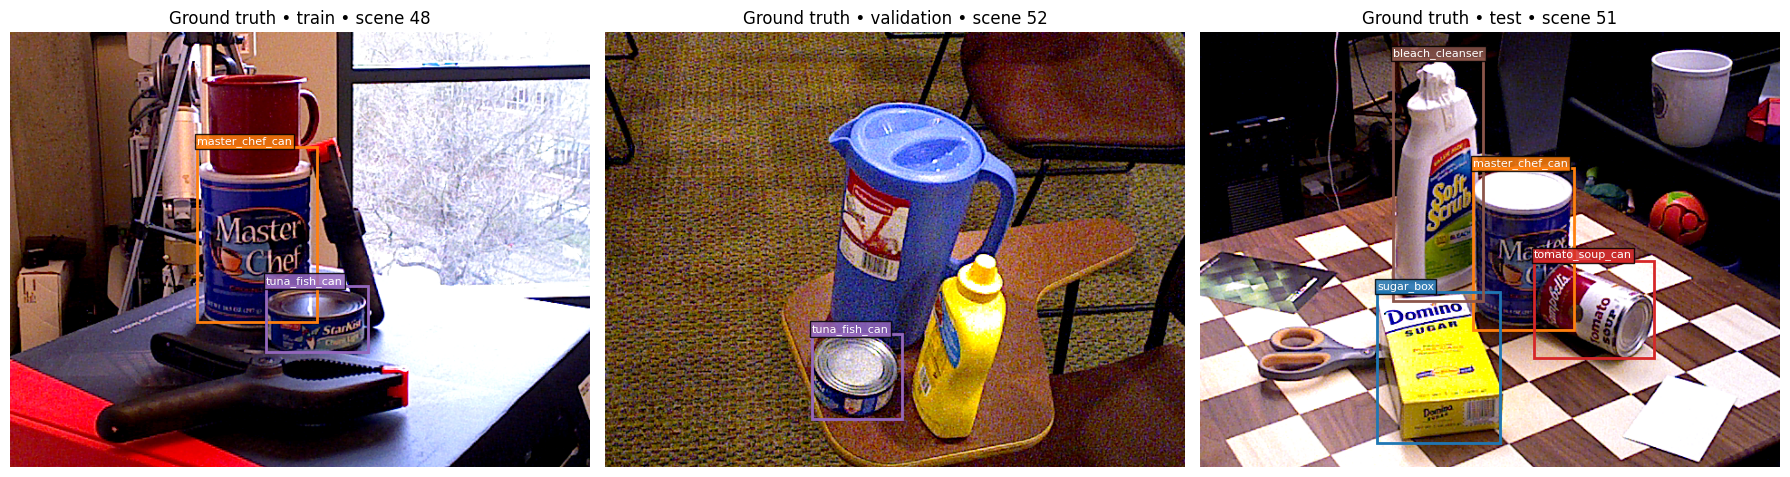

In [5]:
COLORS = ['tab:red','tab:blue','tab:orange','tab:purple','tab:brown']
def draw_boxes(ax, image, boxes, labels, scores=None, title=''):
    ax.imshow(image)
    for i,(b,label) in enumerate(zip(boxes, labels)):
        x0,y0,x1,y1 = [float(v) for v in b]
        label = int(label)
        color = COLORS[(label-1)%len(COLORS)]
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor=color,linewidth=2))
        text = LABEL_TO_NAME[label]
        if scores is not None: text += f' {float(scores[i]):.2f}'
        ax.text(x0,max(0,y0-3),text,fontsize=8,color='white',
                bbox=dict(facecolor=color,alpha=.85,pad=1.5))
    ax.set_title(title); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax,split in zip(axes, ['train','validation','test']):
    row = next((r for r in FRAME_RECORDS[split] if r['labels']), FRAME_RECORDS[split][0])
    with Image.open(row['rgb_path']) as raw: img = raw.convert('RGB').copy()
    draw_boxes(ax,img,row['boxes'],row['labels'],title=f'Ground truth • {split} • scene {row["scene_id"]}')
plt.tight_layout(); plt.savefig(OUT/'full_frame_ground_truth_examples.png', dpi=150); plt.show()

## Part D — PyTorch Detection Dataset and DataLoaders

Torchvision expects images as float RGB tensors in `[0,1]` and each target as an `xyxy` box tensor with **positive** foreground labels. Label `0` is reserved for background and is never placed in `targets['labels']`. The model handles resizing/normalization internally. Empty target lists are retained for legitimate negative frames.

In [6]:
class YCBFrameDetection(Dataset):
    def __init__(self, rows):
        self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, idx):
        record = self.rows[idx]
        with Image.open(record['rgb_path']) as raw: image = TF.to_tensor(raw.convert('RGB'))
        boxes = torch.tensor(record['boxes'],dtype=torch.float32).reshape(-1,4)
        labels = torch.tensor(record['labels'],dtype=torch.int64)
        assert len(boxes) == len(labels)
        assert len(labels) == 0 or bool(((labels >= 1)&(labels < NUM_CLASSES)).all())
        if len(boxes):
            assert bool((boxes[:,2] > boxes[:,0]).all() and (boxes[:,3] > boxes[:,1]).all())
        area = (boxes[:,2]-boxes[:,0]) * (boxes[:,3]-boxes[:,1])
        target = {'boxes':boxes, 'labels':labels,
                  'image_id':torch.tensor([idx],dtype=torch.int64),
                  'area':area, 'iscrowd':torch.zeros(len(boxes),dtype=torch.int64)}
        return image, target

def detection_collate(batch): return tuple(zip(*batch))

datasets = {split:YCBFrameDetection(rows) for split,rows in FRAME_RECORDS.items()}
loaders = {
    split: DataLoader(ds, batch_size=BATCH_SIZE if split=='train' else 1,
                      shuffle=(split=='train'), num_workers=NUM_WORKERS,
                      collate_fn=detection_collate, pin_memory=USE_AMP,
                      generator=torch.Generator().manual_seed(SEED) if split=='train' else None)
    for split,ds in datasets.items()
}

images,targets = next(iter(loaders['train']))
print('Batch tensors:',[tuple(x.shape) for x in images])
print('Targets:',[(tuple(t['boxes'].shape),t['labels'].tolist()) for t in targets])
assert all(x.shape[0]==3 and x.min()>=0 and x.max()<=1 for x in images)

Batch tensors: [(3, 480, 640), (3, 480, 640)]
Targets: [((2, 4), [2, 4]), ((1, 4), [1])]


## Part E — Pretrained Faster R-CNN, five-class predictor and training setup

We fine-tune a COCO-pretrained detector, **replacing** its COCO predictor with a randomly initialized six-output (background + five selected classes) predictor. The MobileNetV3-FPN backbone and detection head see full RGB frames; region proposals and bounding boxes are learned rather than taken from ground truth at inference. `min_size=480` / `max_size=640` keep memory manageable on T4. **No prior Week 08 classification accuracy is used as a detection metric.**

In [7]:
weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
model = fasterrcnn_mobilenet_v3_large_fpn(
    weights=weights,
    trainable_backbone_layers=3,
    min_size=MODEL_MIN_SIZE,
    max_size=MODEL_MAX_SIZE,
    box_detections_per_img=100,
)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model.to(DEVICE)

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                              lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.3)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Model prediction classes (including background):',NUM_CLASSES)

# One real forward-pass sanity check on a labeled training image.
model.train()
images,targets = next(iter(loaders['train']))
images = [im.to(DEVICE) for im in images]
targets = [{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
    losses = model(images,targets)
print('Initial train losses:',{k:round(float(v.detach().cpu()),4) for k,v in losses.items()})
assert all(bool(torch.isfinite(v).all()) for v in losses.values())
del images,targets,losses
if USE_AMP: torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 180MB/s]


Trainable parameters: 18891833
Model prediction classes (including background): 6
Initial train losses: {'loss_classifier': 1.9903, 'loss_box_reg': 0.2315, 'loss_objectness': 0.0839, 'loss_rpn_box_reg': 0.0013}


## Part F — IoU, class-wise precision/recall and AP@0.50

**Matching rule:** each ground-truth box may be matched to at most one *same-class* prediction, at IoU ≥ 0.50. Predictions are processed in descending confidence. All unmatched predictions are false positives and all unmatched annotated objects are false negatives. Operating-point precision/recall/F1 are computed with a **fixed 0.50 confidence cutoff**. AP50 ranks predictions down to the model's 0.05 minimum score and integrates the interpolated precision–recall curve; five-class mAP50 is the mean of five class AP50 values. This is a task-specific internal metric, **not** the official COCO AP@[.50:.95].

In [8]:
@torch.inference_mode()
def collect_predictions(net, loader):
    net.eval()
    predictions, targets = [], []
    for images, batch_targets in tqdm(loader, leave=False, desc='Detect'):
        out = net([x.to(DEVICE,non_blocking=True) for x in images])
        for pred, target in zip(out,batch_targets):
            predictions.append({k:v.detach().cpu() for k,v in pred.items()
                                if k in ('boxes','labels','scores')})
            targets.append({k:v.detach().cpu() for k,v in target.items()})
    return predictions,targets

def safe_div(a,b): return float(a/b) if b else 0.0

def class_matches(predictions,targets,cls,score_threshold, iou_threshold=.5):
    '''Global score-ordered, greedy per-class matching; returns TP/FP/FN/IoUs/AP.'''
    gt_by_image = {}
    matched = {}
    n_gt = 0
    proposals = []
    for image_index,(pred,gt) in enumerate(zip(predictions,targets)):
        gt_boxes = gt['boxes'][gt['labels']==cls]
        gt_by_image[image_index] = gt_boxes
        matched[image_index] = set()
        n_gt += len(gt_boxes)
        indices = torch.where((pred['labels']==cls)&(pred['scores']>=score_threshold))[0]
        for j in indices.tolist():
            proposals.append((float(pred['scores'][j]),image_index,pred['boxes'][j]))
    proposals.sort(key=lambda row:row[0],reverse=True)
    tps, fps, accepted_ious = [], [], []
    for score,image_index,pred_box in proposals:
        gt_boxes = gt_by_image[image_index]
        best_iou, best_idx = 0.0, -1
        if len(gt_boxes):
            overlaps = box_iou(pred_box[None],gt_boxes)[0]
            for j in torch.argsort(overlaps,descending=True).tolist():
                if j not in matched[image_index]:
                    best_iou, best_idx = float(overlaps[j]), j
                    break
        if best_idx >= 0 and best_iou >= iou_threshold:
            matched[image_index].add(best_idx)
            tps.append(1); fps.append(0); accepted_ious.append(best_iou)
        else:
            tps.append(0); fps.append(1)
    TP = int(sum(tps)); FP = int(sum(fps)); FN = int(n_gt-TP)
    return dict(tp=TP,fp=FP,fn=FN,n_gt=n_gt,n_pred=len(proposals),ious=accepted_ious,
                tp_seq=np.asarray(tps,dtype=float),fp_seq=np.asarray(fps,dtype=float))

def area_under_pr_envelope(tp_seq,fp_seq,n_gt):
    if n_gt == 0: return float('nan')
    if len(tp_seq) == 0: return 0.0
    recall = np.cumsum(tp_seq) / n_gt
    precision = np.cumsum(tp_seq) / np.maximum(np.cumsum(tp_seq+fp_seq),1)
    recall = np.r_[0.0,recall,1.0]
    precision = np.r_[0.0,precision,0.0]
    precision = np.maximum.accumulate(precision[::-1])[::-1]
    return float(np.sum((recall[1:]-recall[:-1])*precision[1:]))

def detection_metrics(predictions,targets):
    assert len(predictions)==len(targets)
    rows = []
    total_tp=total_fp=total_fn=0
    all_ious = []
    for cls in range(1,NUM_CLASSES):
        point = class_matches(predictions,targets,cls,SCORE_THRESHOLD,IOU_THRESHOLD)
        ranking = class_matches(predictions,targets,cls,AP_SCORE_FLOOR,IOU_THRESHOLD)
        ap50 = area_under_pr_envelope(ranking['tp_seq'],ranking['fp_seq'],ranking['n_gt'])
        precision = safe_div(point['tp'],point['tp']+point['fp'])
        recall = safe_div(point['tp'],point['tp']+point['fn'])
        rows.append(dict(class_name=LABEL_TO_NAME[cls],support=point['n_gt'],
                         predicted_boxes=point['n_pred'],tp=point['tp'],fp=point['fp'],fn=point['fn'],
                         precision=precision,recall=recall,
                         f1=safe_div(2*precision*recall,precision+recall),
                         ap50=ap50,
                         mean_matched_iou=float(np.mean(point['ious'])) if point['ious'] else np.nan))
        total_tp+=point['tp'];total_fp+=point['fp'];total_fn+=point['fn'];all_ious+=point['ious']
    frame = pd.DataFrame(rows)
    micro_p=safe_div(total_tp,total_tp+total_fp)
    micro_r=safe_div(total_tp,total_tp+total_fn)
    summary = dict(mAP50=float(frame['ap50'].mean()),
                   precision=micro_p,recall=micro_r,
                   f1=safe_div(2*micro_p*micro_r,micro_p+micro_r),
                   tp=total_tp,fp=total_fp,fn=total_fn,
                   mean_matched_iou=float(np.mean(all_ious)) if all_ious else None,
                   evaluated_frames=len(predictions))
    return summary,frame

# Mathematical self-test: two perfect predictions should produce IoU=1 and AP50=1.
_gt = [{'boxes':torch.tensor([[0.,0.,10.,10.],[20.,20.,30.,30.]]),
        'labels':torch.tensor([1,2])}]
_pred = [{'boxes':torch.tensor([[0.,0.,10.,10.],[20.,20.,30.,30.]]),
          'labels':torch.tensor([1,2]),'scores':torch.tensor([.99,.98])}]
assert class_matches(_pred,_gt,1,.50)['tp']==1
assert abs(area_under_pr_envelope(*[class_matches(_pred,_gt,1,.05)[x] for x in ('tp_seq','fp_seq')],1)-1)<1e-8
print('IoU / one-to-one matching / AP50 synthetic checks passed.')

IoU / one-to-one matching / AP50 synthetic checks passed.


## Part G — Train and select the model using **validation only**

Save the best checkpoint by **validation five-class mAP50**, with no test peeking. Train and validation use exactly the same sampled scene-disjoint image sets throughout. Loss components are logged; validation metrics are true detection metrics, not crop-classification accuracy. If Colab disconnects, the checkpoint and epoch history in `/content/week09_outputs` remain available only for that runtime unless copied to Drive.

In [ ]:
def train_one_epoch(net,loader,optimizer,scaler,epoch):
    net.train()
    losses_accum=defaultdict(float); steps=0
    for images,targets in tqdm(loader,desc=f'Train epoch {epoch}',leave=False):
        images=[im.to(DEVICE,non_blocking=True) for im in images]
        targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
            loss_dict=net(images,targets)
            loss=sum(loss_dict.values())
        if not bool(torch.isfinite(loss)):
            raise RuntimeError(f'Non-finite loss in epoch {epoch}: {loss_dict}')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(),max_norm=5.0)
        scaler.step(optimizer);scaler.update()
        for k,v in loss_dict.items(): losses_accum[k]+=float(v.detach().cpu())
        losses_accum['total_loss']+=float(loss.detach().cpu());steps+=1
    return {k:v/steps for k,v in losses_accum.items()}

HISTORY=[]
BEST_SCORE=-1.0
BEST_EPOCH=None
BEST_FILE=CKPT/'week09_best_fasterrcnn_mobilenetv3.pth'
start=time.time()

for epoch in range(1,EPOCHS+1):
    train_losses=train_one_epoch(model,loaders['train'],optimizer,scaler,epoch)
    val_preds,val_targets=collect_predictions(model,loaders['validation'])
    val_summary,_=detection_metrics(val_preds,val_targets)
    row={'epoch':epoch, **train_losses,
         **{'val_'+k:v for k,v in val_summary.items()},
         'learning_rate':optimizer.param_groups[0]['lr']}
    HISTORY.append(row)
    current_score=float(val_summary['mAP50'])
    if current_score > BEST_SCORE:
        BEST_SCORE=current_score; BEST_EPOCH=epoch
        torch.save({'model_state_dict':model.state_dict(),
                    'epoch':epoch,'best_validation_mAP50':BEST_SCORE,
                    'selected_ids':SELECTED_IDS,'seed':SEED,
                    'scene_splits':FIXED_SCENES},BEST_FILE)
        print(f'  New best checkpoint: epoch {epoch}, val mAP50={BEST_SCORE:.4f}')
    print(f'Epoch {epoch:02d}/{EPOCHS}: train loss={train_losses["total_loss"]:.4f} '
          f'| val mAP50={val_summary["mAP50"]:.4f} '
          f'| P={val_summary["precision"]:.3f} R={val_summary["recall"]:.3f}')
    scheduler.step()
    pd.DataFrame(HISTORY).to_csv(OUT/'training_history.csv',index=False)

print('Training time (minutes):',round((time.time()-start)/60,1))
print('Best epoch:',BEST_EPOCH,'| best validation mAP50:',round(BEST_SCORE,4))
assert BEST_FILE.exists()

Train epoch 1:   0%|          | 0/200 [00:00<?, ?it/s]

Detect:   0%|          | 0/100 [00:00<?, ?it/s]

  New best checkpoint: epoch 1, val mAP50=0.6929
Epoch 01/8: train loss=1.0770 | val mAP50=0.6929 | P=0.703 R=0.740


Train epoch 2:   0%|          | 0/200 [00:00<?, ?it/s]

Detect:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 02/8: train loss=0.7110 | val mAP50=0.6863 | P=0.572 R=0.764


... (9 outputs left out)

Train epoch 6:   0%|          | 0/200 [00:00<?, ?it/s]

Detect:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 06/8: train loss=0.2648 | val mAP50=0.6794 | P=0.589 R=0.768


Train epoch 7:   0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
history=pd.DataFrame(HISTORY)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history.epoch,history.total_loss,'o-',label='Train detection loss')
axes[0].set(xlabel='Epoch',ylabel='Loss',title='Training loss');axes[0].grid(alpha=.2)
axes[1].plot(history.epoch,history.val_mAP50,'o-',label='Validation mAP@0.50')
axes[1].axvline(BEST_EPOCH,color='gray',ls='--',alpha=.7,label=f'Best epoch {BEST_EPOCH}')
axes[1].set(xlabel='Epoch',ylabel='mAP@0.50',ylim=(0,1),title='Scene-disjoint validation')
axes[1].grid(alpha=.2);axes[1].legend()
plt.tight_layout();plt.savefig(OUT/'training_curves.png',dpi=160);plt.show()

## Part H — Final validation, one-time held-out test and full-frame predictions

Load the saved best checkpoint selected solely by validation mAP50. The final test set is evaluated **once** for reporting; never use its results to adjust the current experiment. The previously used Week 08 test scenes (51, 59) are still only an *internal repeated-test diagnostic*. Use a new scene split for a truly fresh final assessment later if data permits.

In [11]:
checkpoint=torch.load(BEST_FILE,map_location='cpu',weights_only=False)
assert checkpoint['selected_ids']==SELECTED_IDS
model.load_state_dict(checkpoint['model_state_dict'])
model.to(DEVICE);model.eval()

val_predictions,val_targets=collect_predictions(model,loaders['validation'])
val_final,val_class_metrics=detection_metrics(val_predictions,val_targets)
print('=== BEST-CHECKPOINT VALIDATION ===')
print(json.dumps(val_final,indent=2));display(val_class_metrics)
val_class_metrics.to_csv(OUT/'validation_per_class_metrics.csv',index=False)

test_predictions,test_targets=None,None
test_final,test_class_metrics=None,None
if RUN_FINAL_TEST:
    print('Evaluating previously observed test scenes 51 and 59 ONCE for this run ...')
    test_predictions,test_targets=collect_predictions(model,loaders['test'])
    test_final,test_class_metrics=detection_metrics(test_predictions,test_targets)
    print('=== REPEATED HELD-OUT TEST (NOT OFFICIAL BOP SCORE) ===')
    print(json.dumps(test_final,indent=2));display(test_class_metrics)
    test_class_metrics.to_csv(OUT/'test_per_class_metrics.csv',index=False)

def serialized_predictions(preds, rows):
    return [{'scene_id':r['scene_id'],'im_id':r['im_id'],
             'boxes':p['boxes'].tolist(),'labels':p['labels'].tolist(),
             'scores':p['scores'].tolist()} for p,r in zip(preds,rows)]

with open(OUT/'validation_predictions.json','w') as f:
    json.dump(serialized_predictions(val_predictions,FRAME_RECORDS['validation']),f)
if RUN_FINAL_TEST:
    with open(OUT/'test_predictions.json','w') as f:
        json.dump(serialized_predictions(test_predictions,FRAME_RECORDS['test']),f)

Detect:   0%|          | 0/100 [00:00<?, ?it/s]

=== BEST-CHECKPOINT VALIDATION ===
{
  "mAP50": 0.6969847672150853,
  "precision": 0.5894428152492669,
  "recall": 0.804,
  "f1": 0.6802030456852792,
  "tp": 201,
  "fp": 140,
  "fn": 49,
  "mean_matched_iou": 0.8291124493921574,
  "evaluated_frames": 100
}


,class_name,support,predicted_boxes,tp,fp,fn,precision,recall,f1,ap50,mean_matched_iou
0,tomato_soup_can,50,103,50,53,0,0.485437,1.00,0.653595,0.987433,0.857426
1,sugar_box,50,46,44,2,6,0.956522,0.88,0.916667,0.970134,0.788158
2,master_chef_can,50,100,50,50,0,0.500000,1.00,0.666667,0.500000,0.855494
3,tuna_fish_can,50,50,50,0,0,1.000000,1.00,1.000000,1.000000,0.839308
4,bleach_cleanser,50,42,7,35,43,0.166667,0.14,0.152174,0.027357,0.623032


Evaluating previously observed test scenes 51 and 59 ONCE for this run ...


Detect:   0%|          | 0/100 [00:00<?, ?it/s]

=== REPEATED HELD-OUT TEST (NOT OFFICIAL BOP SCORE) ===
{
  "mAP50": 0.8670733518398451,
  "precision": 0.8498168498168498,
  "recall": 0.7733333333333333,
  "f1": 0.8097731239092495,
  "tp": 232,
  "fp": 41,
  "fn": 68,
  "mean_matched_iou": 0.8480894085148285,
  "evaluated_frames": 100
}


,class_name,support,predicted_boxes,tp,fp,fn,precision,recall,f1,ap50,mean_matched_iou
0,tomato_soup_can,100,57,50,7,50,0.877193,0.50,0.636943,0.659185,0.902115
1,sugar_box,50,55,50,5,0,0.909091,1.00,0.952381,1.000000,0.860792
2,master_chef_can,50,50,50,0,0,1.000000,1.00,1.000000,1.000000,0.876640
3,tuna_fish_can,50,65,50,15,0,0.769231,1.00,0.869565,0.999231,0.828464
4,bleach_cleanser,50,46,32,14,18,0.695652,0.64,0.666667,0.676951,0.729881


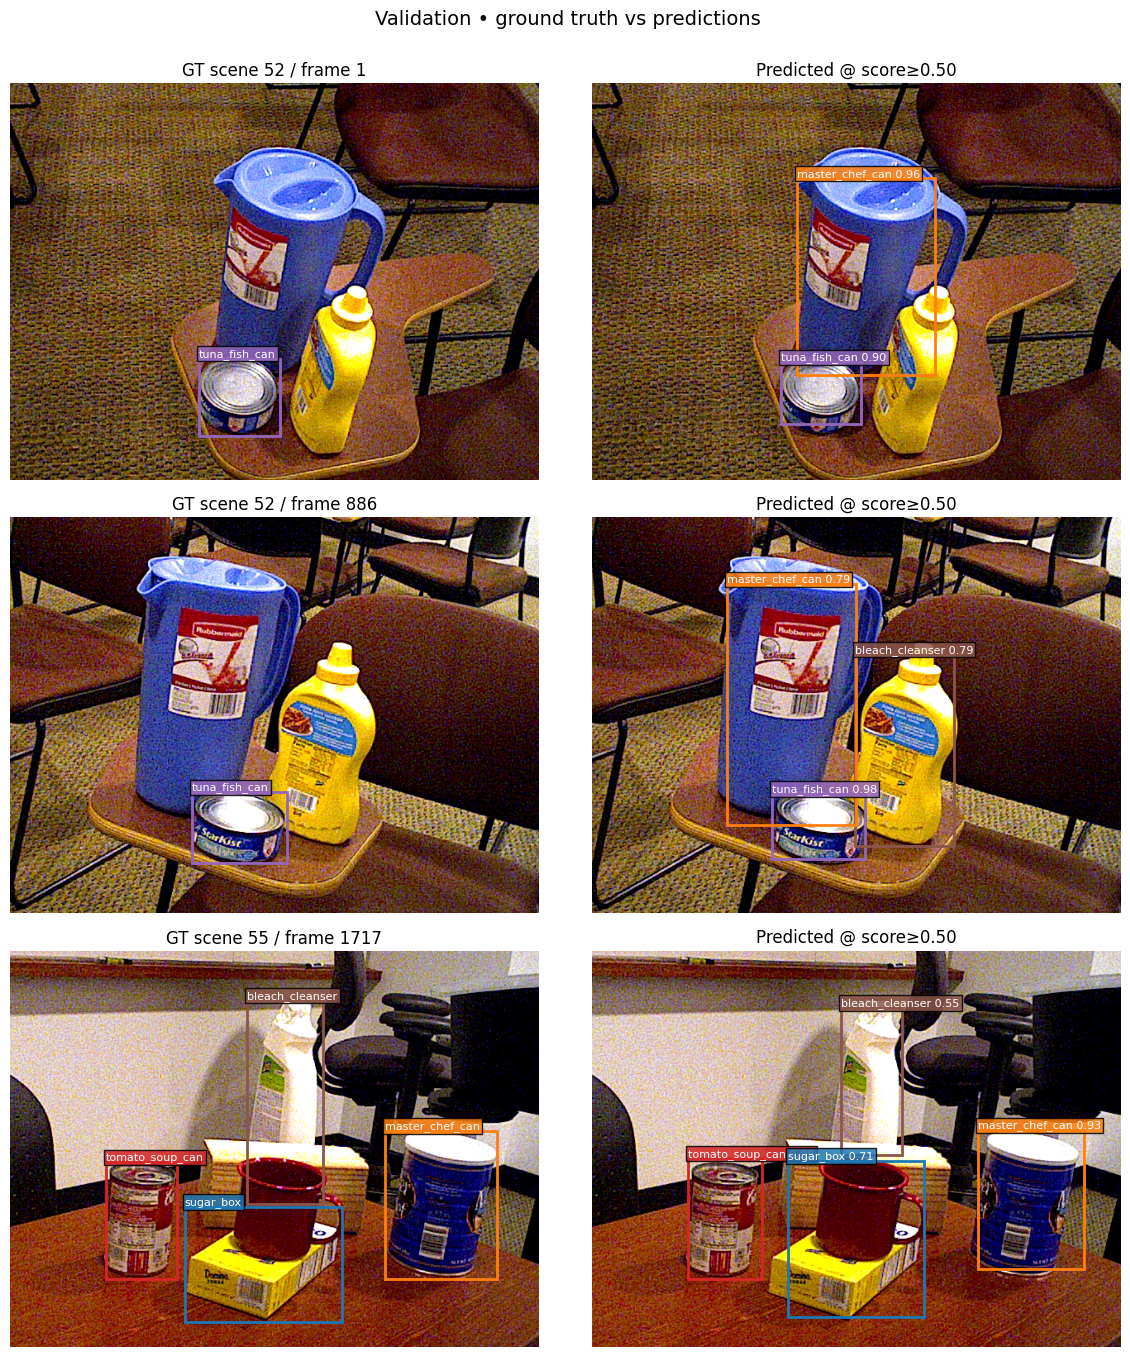

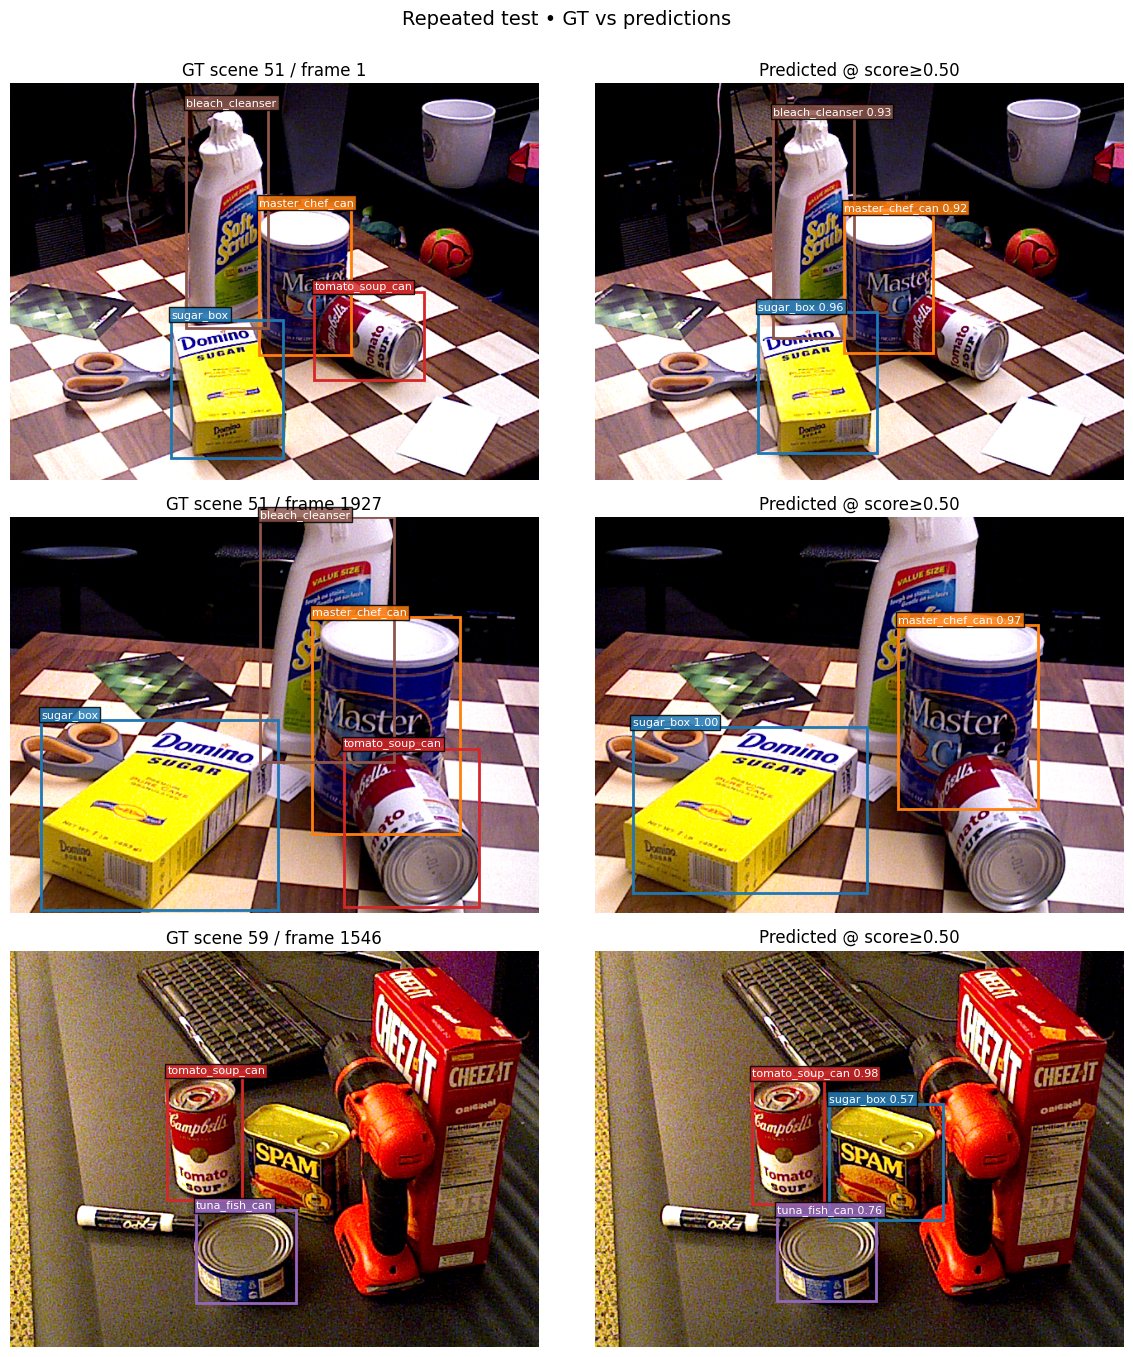

In [12]:
def show_predictions(rows,preds,indices,save_path,title):
    fig,axes=plt.subplots(len(indices),2,figsize=(12,4.5*len(indices)),squeeze=False)
    for row_ix,i in enumerate(indices):
        rec,pred=rows[i],preds[i]
        with Image.open(rec['rgb_path']) as raw: img=raw.convert('RGB').copy()
        draw_boxes(axes[row_ix,0],img,rec['boxes'],rec['labels'],
                   title=f'GT scene {rec["scene_id"]} / frame {rec["im_id"]}')
        keep=pred['scores']>=SCORE_THRESHOLD
        draw_boxes(axes[row_ix,1],img,pred['boxes'][keep],pred['labels'][keep],
                   pred['scores'][keep],title=f'Predicted @ score≥{SCORE_THRESHOLD:.2f}')
    fig.suptitle(title,y=1.002,fontsize=14)
    plt.tight_layout();plt.savefig(save_path,dpi=145,bbox_inches='tight');plt.show()

sample_ids=np.linspace(0,len(FRAME_RECORDS['validation'])-1,min(3,len(val_predictions)),dtype=int).tolist()
show_predictions(FRAME_RECORDS['validation'],val_predictions,sample_ids,
                 OUT/'validation_detection_examples.png','Validation • ground truth vs predictions')
if RUN_FINAL_TEST:
    test_sample_ids=np.linspace(0,len(FRAME_RECORDS['test'])-1,min(3,len(test_predictions)),dtype=int).tolist()
    show_predictions(FRAME_RECORDS['test'],test_predictions,test_sample_ids,
                     OUT/'test_detection_examples.png','Repeated test • GT vs predictions')

## Part I — Failure analysis, saved results and report-ready conclusions

For each frame, count TP, FP, and FN with the fixed IoU/score thresholds; display the most error-heavy **validation** frames (not selected from the test). Diagnose *missed objects, extra detections, overlapping boxes and poor localization*, not just wrong classes. Since only five of YCB-V's 21 object categories are labelled as foreground, some apparent detector false positives may involve other real objects: discuss this limitation explicitly rather than assigning a definitive cause.

,index,scene_id,im_id,tp,fp,fn,total_errors
52,52,55,62,2,2,2,4
58,58,55,526,2,2,2,4
51,51,55,42,2,1,2,3
54,54,55,128,2,1,2,3
53,53,55,89,3,2,1,3
55,55,55,205,3,2,1,3
56,56,55,454,3,2,1,3
57,57,55,512,3,2,1,3
59,59,55,530,3,2,1,3
60,60,55,562,3,2,1,3


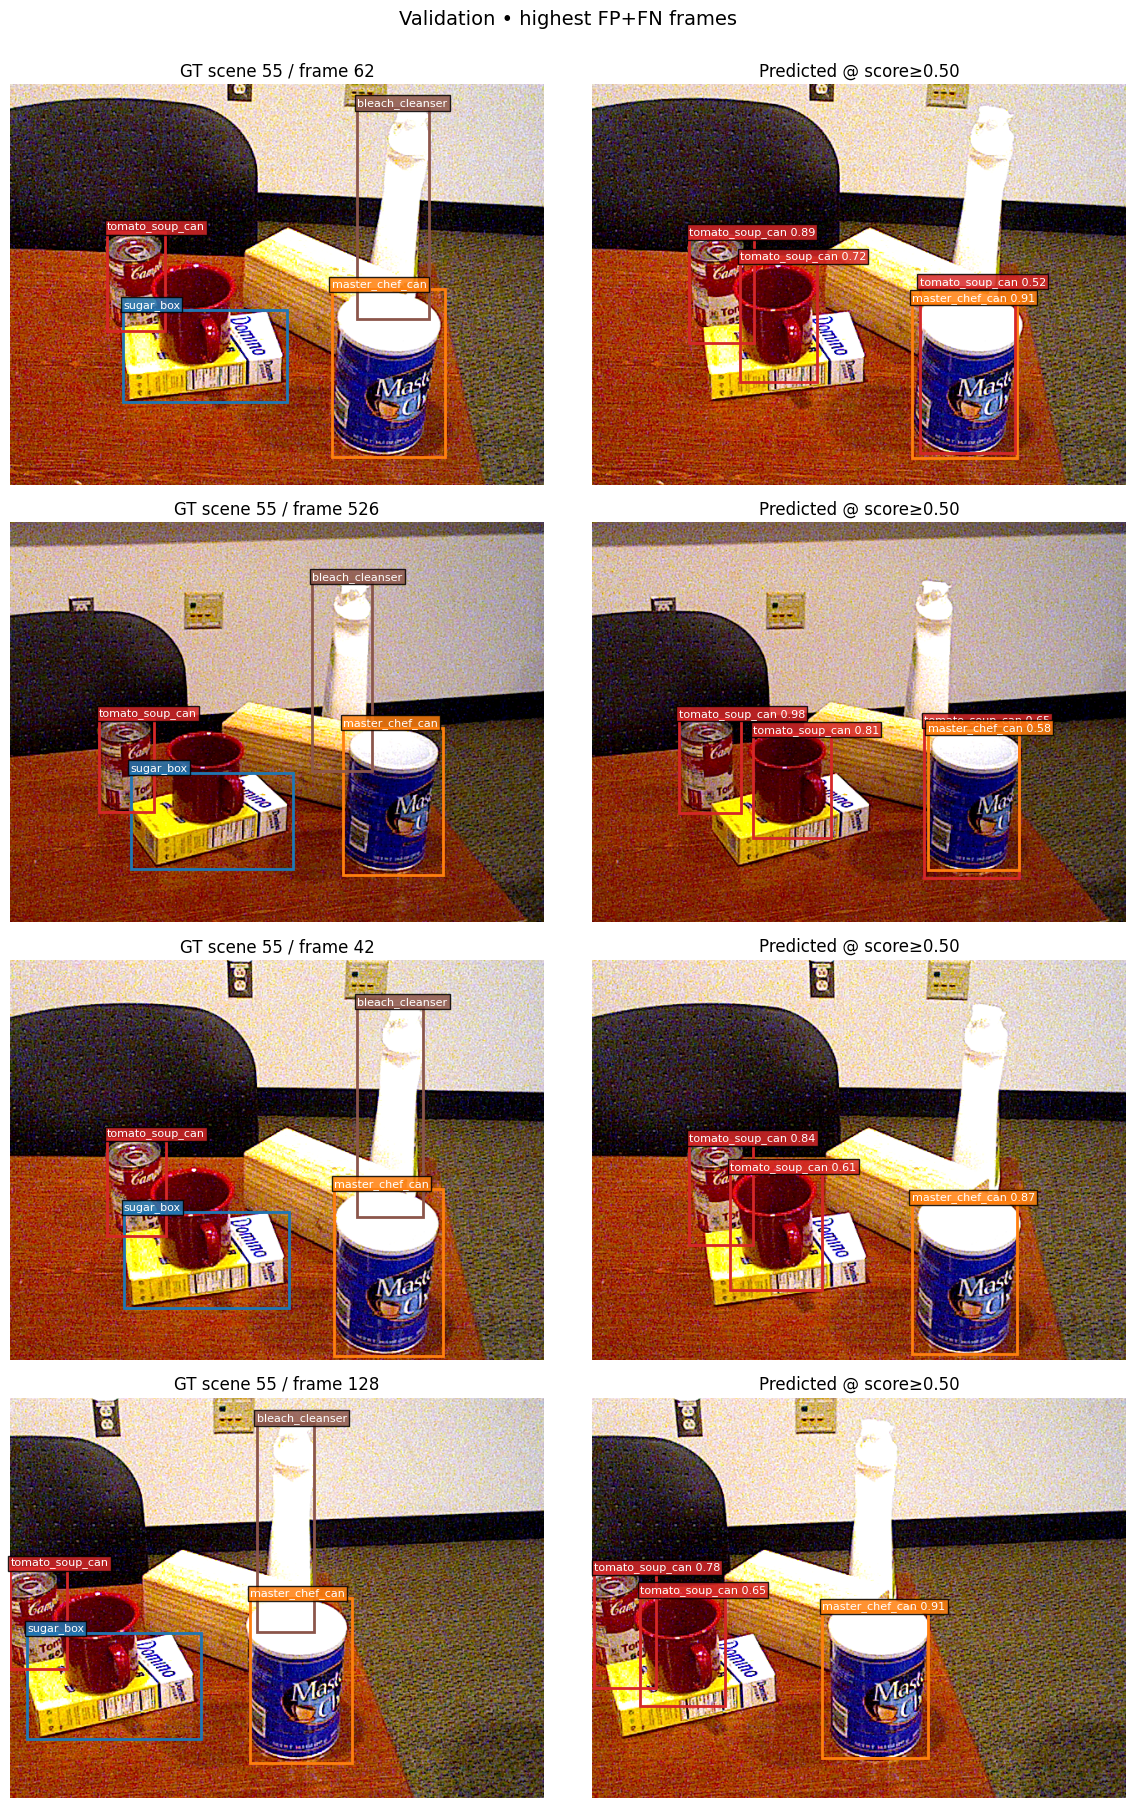

Suggested failure-analysis questions:
• Are false negatives concentrated on small, partially hidden or overlapping objects?
• Are false positives actually unlabeled YCB object categories?
• Does the box cover the correct object but miss IoU≥0.50?
• Does poor precision stem from background confusion or duplicate boxes?


In [13]:
def per_frame_error_table(preds,targs,rows):
    result=[]
    for i,(pred,gt,rec) in enumerate(zip(preds,targs,rows)):
        tp=fp=fn=0
        for cls in range(1,NUM_CLASSES):
            m=class_matches([pred],[gt],cls,SCORE_THRESHOLD,IOU_THRESHOLD)
            tp+=m['tp'];fp+=m['fp'];fn+=m['fn']
        result.append(dict(index=i,scene_id=rec['scene_id'],im_id=rec['im_id'],
                           tp=tp,fp=fp,fn=fn,total_errors=fp+fn))
    return pd.DataFrame(result).sort_values(['total_errors','fn','fp'],ascending=False)

val_errors=per_frame_error_table(val_predictions,val_targets,FRAME_RECORDS['validation'])
display(val_errors.head(12))
val_errors.to_csv(OUT/'validation_frame_errors.csv',index=False)
hard_ids=val_errors.head(min(4,len(val_errors)))['index'].astype(int).tolist()
show_predictions(FRAME_RECORDS['validation'],val_predictions,hard_ids,
                 OUT/'validation_hard_examples.png','Validation • highest FP+FN frames')

print('Suggested failure-analysis questions:')
print('• Are false negatives concentrated on small, partially hidden or overlapping objects?')
print('• Are false positives actually unlabeled YCB object categories?')
print('• Does the box cover the correct object but miss IoU≥0.50?')
print('• Does poor precision stem from background confusion or duplicate boxes?')

In [14]:
def json_clean(v):
    if isinstance(v,dict): return {k:json_clean(x) for k,x in v.items()}
    if isinstance(v,list): return [json_clean(x) for x in v]
    if isinstance(v,tuple): return [json_clean(x) for x in v]
    if isinstance(v,np.generic): return v.item()
    if isinstance(v,float) and not math.isfinite(v): return None
    return v

result={
    'intern':'Mehrana Rezaei',
    'week':9,'task':'Full-frame five-class YCB-V object detection',
    'note':'Internal BOP19 repeated-scene evaluation, NOT official BOP score',
    'model':'Torchvision FasterRCNN-MobileNetV3-Large-FPN (COCO pretrained)',
    'class_ids':SELECTED_IDS,'class_names':[LABEL_TO_NAME[i] for i in range(1,NUM_CLASSES)],
    'seed':SEED,'scene_split':FIXED_SCENES,
    'max_frames_per_scene':MAX_FRAMES_PER_SCENE,
    'min_visibility':MIN_VISIBILITY,'min_box_side_px':MIN_BOX_SIDE,
    'num_epochs':EPOCHS,'best_epoch':BEST_EPOCH,
    'best_validation_mAP50':BEST_SCORE,
    'iou_threshold':IOU_THRESHOLD,'score_threshold':SCORE_THRESHOLD,
    'ap_score_floor':AP_SCORE_FLOOR,
    'split_summary':split_summary.to_dict(orient='records'),
    'validation_metrics':val_final,
    'test_metrics':test_final,
    'limitations':[
        'Only five selected classes are annotated as positives; other visible YCB objects are untreated background.',
        'Filtering small/low-visibility selected objects leaves partial detection labels.',
        'Scenes 51 and 59 were viewed in preceding weeks, so test results are not a fresh benchmark.',
        'Only one fixed seed and a limited frames-per-scene sample are evaluated.',
        'mAP50 is a custom five-class internal metric, not official COCO/BOP benchmark AP.'
    ]
}
with open(OUT/'week09_final_result.json','w') as f:
    json.dump(json_clean(result),f,indent=2)

print('=== WEEK 09 TECHNICAL REPORT VALUES ===')
print('Scenes:',FIXED_SCENES)
print('Frames per split:',{x:len(y) for x,y in FRAME_RECORDS.items()})
print('Best epoch:',BEST_EPOCH)
print('Validation metrics:',json.dumps(json_clean(val_final),indent=2))
print('Repeated held-out test:',json.dumps(json_clean(test_final),indent=2))
print('Saved outputs:',OUT)
print('Checkpoint:',BEST_FILE)

=== WEEK 09 TECHNICAL REPORT VALUES ===
Scenes: {'train': [48, 49, 50, 53, 54, 56, 57, 58], 'validation': [52, 55], 'test': [51, 59]}
Frames per split: {'train': 400, 'validation': 100, 'test': 100}
Best epoch: 4
Validation metrics: {
  "mAP50": 0.6969847672150853,
  "precision": 0.5894428152492669,
  "recall": 0.804,
  "f1": 0.6802030456852792,
  "tp": 201,
  "fp": 140,
  "fn": 49,
  "mean_matched_iou": 0.8291124493921574,
  "evaluated_frames": 100
}
Repeated held-out test: {
  "mAP50": 0.8670733518398451,
  "precision": 0.8498168498168498,
  "recall": 0.7733333333333333,
  "f1": 0.8097731239092495,
  "tp": 232,
  "fp": 41,
  "fn": 68,
  "mean_matched_iou": 0.8480894085148285,
  "evaluated_frames": 100
}
Saved outputs: /content/week09_outputs
Checkpoint: /content/week09_outputs/checkpoints/week09_best_fasterrcnn_mobilenetv3.pth
